# 01 - Exploratory Data Analysis

Tujuan : memahami data sebelum membuat preprocessing dan model.
Alur: (1) load data, (2) gambaran umum, (3) target, (4) fitur numerik, (5) fitur kategorikal, (6) lokasi, (7) train vs test, (8) kesimpulan.

## 0. Import, konfigurasi, dan fungsi bantu

In [14]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

# Notebook ada di notebooks/, jadi data ada di ../data
DATA_DIR = Path("../data")
FIG_DIR = Path("../reports/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

TARGET = "damage_grade"
NUM_COLS = ["count_floors_pre_eq", "age_building", "plinth_area_sq_ft", "height_ft_pre_eq"]
CAT_COLS = ["land_surface_condition", "foundation_type", "roof_type", "ground_floor_type",
            "other_floor_type", "position", "plan_configuration", "superstructure"]


def load_data(data_dir):
    """Membaca train.csv dan test.csv dari folder data.

    Args:
        data_dir (Path): Folder yang berisi train.csv dan test.csv.

    Returns:
        tuple[pd.DataFrame, pd.DataFrame]: DataFrame train dan test.
    """
    train = pd.read_csv(data_dir / "train.csv")
    test = pd.read_csv(data_dir / "test.csv")
    return train, test


def save_fig(name):
    """Menyimpan figure matplotlib yang sedang aktif ke reports/figures/.

    Args:
        name (str): Nama file gambar, misalnya "target_distribution.png".
    """
    plt.tight_layout()
    plt.savefig(FIG_DIR / name, dpi=150)


def plot_target_distribution(df, order):
    """Membuat countplot distribusi kelas target.

    Args:
        df (pd.DataFrame): Data train yang memuat kolom target.
        order (list[str]): Urutan kelas pada sumbu x.
    """
    fig, ax = plt.subplots(figsize=(6, 4))
    sns.countplot(data=df, x=TARGET, order=order, ax=ax)
    ax.set_title("Distribusi damage_grade")
    save_fig("target_distribution.png")
    plt.show()


def plot_numeric(df, columns, order, kind="hist"):
    """Membuat grid histogram atau boxplot untuk fitur numerik.

    Nilai di atas persentil 99 dibuang dari grafik agar outlier tidak
    merusak skala. Untuk kind="box", age_building == 999 juga dibuang.

    Args:
        df (pd.DataFrame): Data train.
        columns (list[str]): Kolom numerik yang digambar.
        order (list[str]): Urutan kelas target (dipakai untuk boxplot).
        kind (str): "hist" untuk histogram, "box" untuk boxplot terhadap target.
    """
    data = df[df["age_building"] < 999] if kind == "box" else df
    fig, axes = plt.subplots(2, 2, figsize=(12, 8))
    for ax, col in zip(axes.ravel(), columns):
        sub = data[data[col] <= data[col].quantile(0.99)]
        if kind == "hist":
            sns.histplot(sub[col], bins=40, ax=ax)
            ax.set_title(f"{col} (<= persentil 99)")
        else:
            sns.boxplot(data=sub, x=TARGET, y=col, order=order, ax=ax)
            ax.set_title(f"{col} vs {TARGET}")
    save_fig("numeric_distributions.png" if kind == "hist" else "numeric_vs_target.png")
    plt.show()


def summarize_categorical(train, test, columns):
    """Mencetak frekuensi tiap kategori dan kategori test yang tidak ada di train.

    Args:
        train (pd.DataFrame): Data train.
        test (pd.DataFrame): Data test.
        columns (list[str]): Kolom kategorikal yang diperiksa.
    """
    for col in columns:
        print(f"\n{col}  (unik train={train[col].nunique()}, unik test={test[col].nunique()})")
        print(train[col].value_counts().head(10))
        unseen = set(test[col]) - set(train[col])
        if unseen:
            print("  !! kategori di test yang tidak ada di train:", unseen)


def plot_target_heatmap(df, col, filename):
    """Membuat heatmap proporsi damage_grade untuk setiap nilai sebuah kolom.

    Setiap baris dinormalisasi sehingga jumlahnya 1.

    Args:
        df (pd.DataFrame): Data train.
        col (str): Kolom fitur yang dibandingkan dengan target.
        filename (str): Nama file gambar hasil.
    """
    ct = pd.crosstab(df[col], df[TARGET], normalize="index")
    fig, ax = plt.subplots(figsize=(8, 0.6 * len(ct) + 2))
    sns.heatmap(ct, annot=True, fmt=".2f", cmap="YlOrRd", ax=ax)
    ax.set_title(f"{TARGET} per {col}")
    save_fig(filename)
    plt.show()


def compare_train_test(train, test, col):
    """Membandingkan proporsi kategori sebuah kolom antara train dan test.

    Args:
        train (pd.DataFrame): Data train.
        test (pd.DataFrame): Data test.
        col (str): Nama kolom yang dibandingkan.

    Returns:
        pd.DataFrame: Tabel proporsi dengan kolom "train" dan "test".
    """
    return pd.concat([train[col].value_counts(normalize=True).rename("train"),
                      test[col].value_counts(normalize=True).rename("test")], axis=1).round(3)

## 1. Load data

In [15]:
train, test = load_data(DATA_DIR)
print("train:", train.shape, "| test:", test.shape)

train: (533465, 17) | test: (228629, 16)


## 2. Gambaran umum

In [16]:
display(train.head())
train.info()

,building_id,district_id,vdcmun_id,ward_id,count_floors_pre_eq,age_building,plinth_area_sq_ft,height_ft_pre_eq,land_surface_condition,foundation_type,roof_type,ground_floor_type,other_floor_type,position,plan_configuration,damage_grade,superstructure
0,280803013271,28,2802,280202,3,42,504,21,Flat,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Mud,TImber/Bamboo-Mud,Attached-2 side,Rectangular,Grade 5,has_superstructure_mud_mortar_stone
1,311908002031,31,3104,310416,2,8,380,16,Flat,Cement-Stone/Brick,Bamboo/Timber-Heavy roof,Mud,Timber-Planck,Not attached,Rectangular,Grade 1,has_superstructure_cement_mortar_brick
2,310303000362,31,3111,311106,2,37,375,16,Moderate slope,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Mud,TImber/Bamboo-Mud,Not attached,Rectangular,Grade 5,has_superstructure_mud_mortar_stone
3,280806040201,28,2802,280206,2,70,319,15,Flat,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Mud,TImber/Bamboo-Mud,Attached-1 side,Rectangular,Grade 3,has_superstructure_adobe_mud
4,291301000371,29,2904,290404,1,25,495,6,Flat,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Brick/Stone,Not applicable,Not attached,Rectangular,Grade 4,has_superstructure_mud_mortar_stone


<class 'pandas.DataFrame'>
RangeIndex: 533465 entries, 0 to 533464
Data columns (total 17 columns):
 #   Column                  Non-Null Count   Dtype
---  ------                  --------------   -----
 0   building_id             533465 non-null  int64
 1   district_id             533465 non-null  int64
 2   vdcmun_id               533465 non-null  int64
 3   ward_id                 533465 non-null  int64
 4   count_floors_pre_eq     533465 non-null  int64
 5   age_building            533465 non-null  int64
 6   plinth_area_sq_ft       533465 non-null  int64
 7   height_ft_pre_eq        533465 non-null  int64
 8   land_surface_condition  533465 non-null  str  
 9   foundation_type         533465 non-null  str  
 10  roof_type               533465 non-null  str  
 11  ground_floor_type       533465 non-null  str  
 12  other_floor_type        533465 non-null  str  
 13  position                533465 non-null  str  
 14  plan_configuration      533465 non-null  str  
 15  damage_grad

In [17]:
print("Hanya di train:", set(train.columns) - set(test.columns))
print("Missing train :", train.isna().sum().sum(), "| Missing test:", test.isna().sum().sum())
print("Duplikat building_id train:", train["building_id"].duplicated().sum())
print("building_id sama di train & test:", len(set(train["building_id"]) & set(test["building_id"])))

Hanya di train: {'damage_grade'}
Missing train : 0 | Missing test: 0
Duplikat building_id train: 0
building_id sama di train & test: 0


**interpretasi:** Data bersih, tidak ada missing value dan tidak ada building_id duplikat. Tidak ada bangunan yang sama di train dan test, jadi tidak ada kebocoran lewat ID. Satu-satunya kolom yang hanya ada di train adalah target damage_grade, sesuai yang diharapkan. Preprocessing tidak perlu imputasi untuk nilai kosong, tapi tetap perlu menangani nilai tidak wajar (misalnya umur 999).

## 3. Distribusi target
Kelas tidak seimbang. Ini penting karena metriknya **Macro F1** (setiap kelas bobotnya sama).

damage_grade
Grade 1    0.1034
Grade 2    0.1145
Grade 3    0.1790
Grade 4    0.2412
Grade 5    0.3619
Name: proportion, dtype: float64


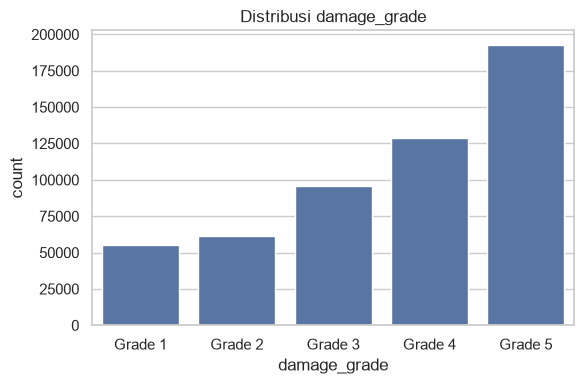

In [18]:
order = sorted(train[TARGET].unique())
print(train[TARGET].value_counts(normalize=True).loc[order].round(4))
plot_target_distribution(train, order)

**Interpretasi Distribusi Target :**

Berdasarkan grafik distribusi `damage_grade`, jumlah observasi meningkat dari Grade 1 hingga Grade 5. Grade 5 memiliki jumlah observasi terbanyak, sedangkan Grade 1 memiliki jumlah observasi paling sedikit. Berdasarkan proporsi kelas, Grade 5 mencakup 36,19% data train, sementara Grade 1 hanya mencakup 10,34%.

Pola tersebut menunjukkan adanya ketidakseimbangan kelas (*class imbalance*). Jumlah observasi Grade 5 sekitar 3,5 kali jumlah observasi Grade 1. Kondisi ini perlu diperhatikan karena model berpotensi lebih mudah mempelajari kelas yang memiliki lebih banyak sampel.

Karena kompetisi menggunakan Macro F1-Score sebagai metrik evaluasi, performa model perlu diperhatikan pada seluruh kelas, bukan hanya kelas dominan. Oleh karena itu, validasi stratified dan evaluasi F1-score per kelas akan dipertimbangkan dalam proses pemodelan. Penanganan ketidakseimbangan kelas akan ditentukan berdasarkan hasil validasi.

## 4. Fitur numerik

In [19]:
display(train[NUM_COLS].describe().T)
print("age_building == 999 :", (train["age_building"] == 999).sum(), "(train) |", (test["age_building"] == 999).sum(), "(test)")
print("age_building >= 100 :", (train["age_building"] >= 100).sum())
print("height_ft_pre_eq >= 60:", (train["height_ft_pre_eq"] >= 60).sum())
print("count_floors_pre_eq:", train["count_floors_pre_eq"].value_counts().sort_index().to_dict())

,count,mean,std,min,25%,50%,75%,max
count_floors_pre_eq,533465.0,2.088000,0.655001,1.0,2.0,2.0,2.0,9.0
age_building,533465.0,24.337319,64.999055,0.0,9.0,16.0,27.0,999.0
plinth_area_sq_ft,533465.0,406.523453,226.610477,70.0,280.0,358.0,470.0,5000.0
height_ft_pre_eq,533465.0,16.047675,5.490926,6.0,12.0,16.0,18.0,99.0


age_building == 999 : 2198 (train) | 946 (test)
age_building >= 100 : 4473
height_ft_pre_eq >= 60: 372
count_floors_pre_eq: {1: 83177, 2: 327666, 3: 116918, 4: 4318, 5: 1079, 6: 235, 7: 52, 8: 9, 9: 11}


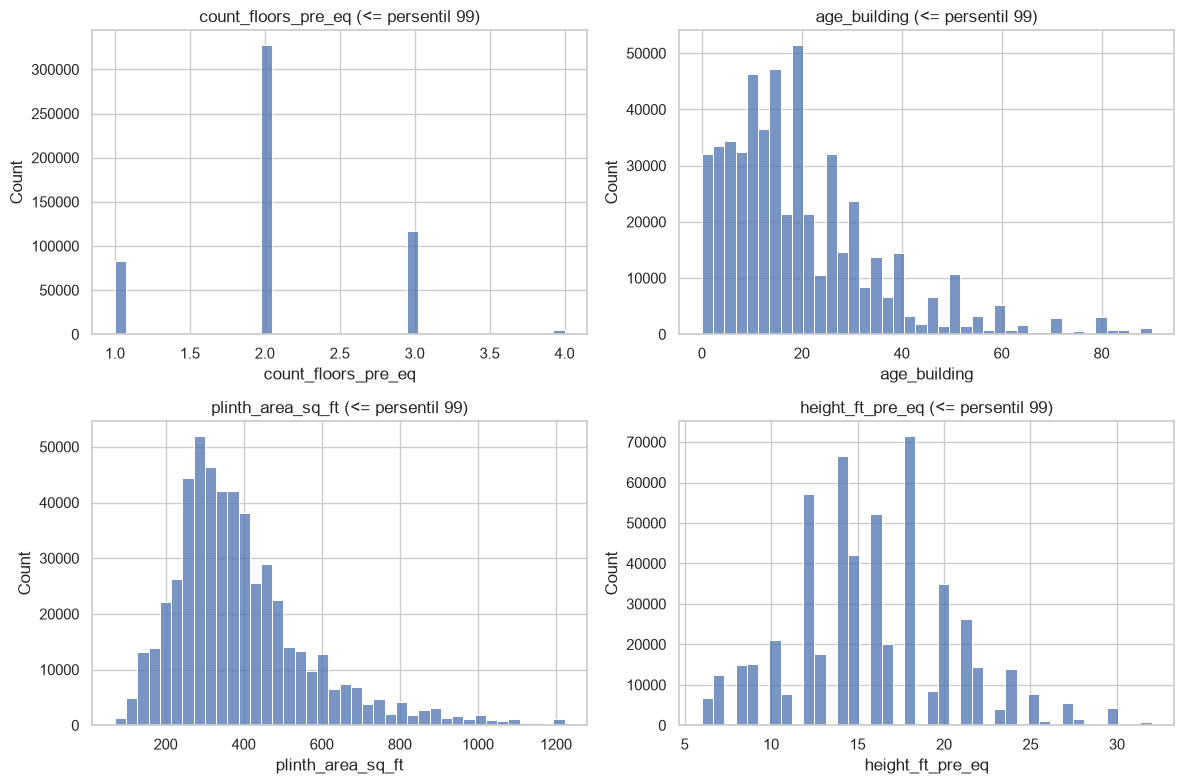

In [7]:
plot_numeric(train, NUM_COLS, order, kind="hist")

### Interpretasi Distribusi Fitur Numerik

Berdasarkan histogram, distribusi setiap fitur numerik memiliki pola yang berbeda.

1. **`count_floors_pre_eq`**: jumlah lantai didominasi oleh bangunan dua lantai, diikuti bangunan tiga lantai dan satu lantai. Bangunan dengan empat lantai atau lebih jumlahnya jauh lebih sedikit. Hal ini menunjukkan bahwa distribusi jumlah lantai terkonsentrasi pada bangunan bertingkat rendah.

2. **`age_building`**: sebagian besar bangunan memiliki usia relatif rendah, dengan frekuensi yang cenderung menurun pada usia yang lebih tinggi. Distribusi menunjukkan kemencengan ke kanan. Nilai `age_building = 999` perlu diperiksa secara terpisah karena kemungkinan merupakan kode khusus, bukan usia bangunan yang sebenarnya. Histogram yang ditampilkan juga dibatasi hingga persentil ke-99 sehingga tidak memperlihatkan seluruh rentang nilai asli.

3. **`plinth_area_sq_ft`**: distribusi luas bangunan terkonsentrasi pada rentang yang relatif rendah, dengan ekor memanjang ke kanan. Pola ini menunjukkan bahwa sebagian kecil bangunan memiliki luas yang jauh lebih besar dibandingkan mayoritas observasi. Nilai ekstrem perlu diperiksa sebelum menentukan apakah diperlukan transformasi atau penanganan khusus.

4. **`height_ft_pre_eq`**: tinggi bangunan tersebar pada beberapa nilai dengan konsentrasi utama di sekitar rentang 12–18 kaki. Terdapat pula sejumlah bangunan yang lebih tinggi daripada mayoritas observasi. Nilai ekstrem perlu diperiksa untuk memastikan apakah merupakan pengamatan valid atau kesalahan pencatatan.

Secara keseluruhan, histogram menunjukkan bahwa fitur numerik tidak semuanya mengikuti distribusi simetris. Pemeriksaan nilai ekstrem dan pemahaman karakteristik setiap fitur diperlukan sebelum menentukan preprocessing. Nilai ekstrem tidak akan langsung dihapus hanya berdasarkan bentuk histogram.

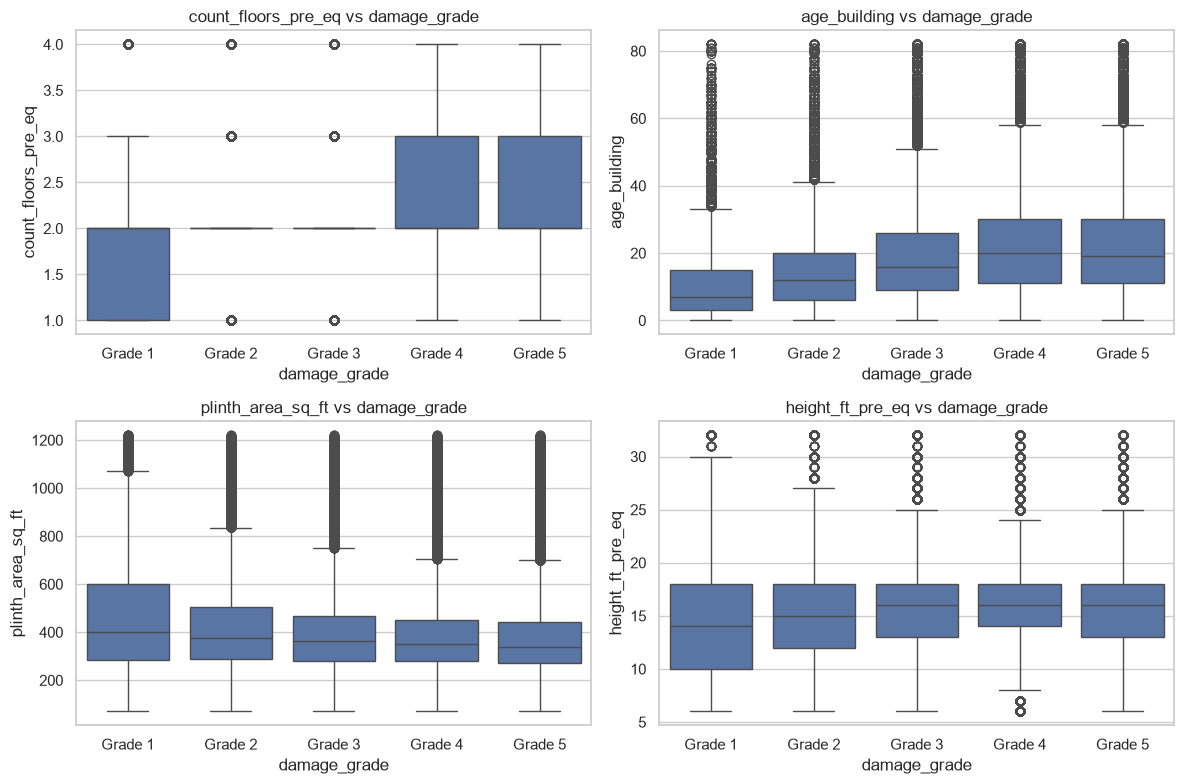

In [8]:
plot_numeric(train, NUM_COLS, order, kind="box")

### Interpretasi Fitur Numerik terhadap Target

Berdasarkan boxplot, terdapat beberapa pola perbedaan distribusi fitur numerik antar-kelas `damage_grade`.

1. **`count_floors_pre_eq`**: distribusi jumlah lantai pada Grade 1–3 cenderung terkonsentrasi pada nilai yang lebih rendah, sedangkan Grade 4–5 menunjukkan sebaran yang lebih tinggi. Pola ini mengindikasikan bahwa jumlah lantai berpotensi memberikan informasi untuk membedakan kelas kerusakan, meskipun distribusi antar-kelas masih dapat saling tumpang tindih.

2. **`age_building`**: median usia bangunan cenderung meningkat dari Grade 1 menuju Grade 4–5. Hal ini menunjukkan adanya asosiasi antara usia bangunan dan tingkat kerusakan pada data. Namun, boxplot saja tidak membuktikan hubungan sebab-akibat, dan pola tersebut perlu dievaluasi bersama fitur struktural lainnya.

3. **`plinth_area_sq_ft`**: median luas bangunan terlihat cenderung menurun pada kelas kerusakan yang lebih tinggi. Walaupun demikian, rentang antarkelas saling tumpang tindih dan terdapat banyak nilai ekstrem. Oleh karena itu, luas bangunan tidak dapat digunakan sebagai satu-satunya dasar untuk membedakan tingkat kerusakan.

4. **`height_ft_pre_eq`**: median tinggi bangunan menunjukkan kecenderungan sedikit meningkat pada kelas yang lebih tinggi, tetapi distribusi antarkelas masih banyak tumpang tindih. Fitur ini mungkin memberikan informasi tambahan, tetapi kekuatan hubungannya dengan target perlu diuji melalui pemodelan.

Secara keseluruhan, boxplot menunjukkan indikasi bahwa jumlah lantai, usia bangunan, luas bangunan, dan tinggi bangunan memiliki pola distribusi yang berbeda antar-kelas. Fitur-fitur tersebut layak dipertahankan untuk eksperimen awal. Besarnya kontribusi setiap fitur terhadap performa prediksi belum dapat ditentukan hanya dari visualisasi ini.

## 5. Fitur kategorikal

In [9]:
summarize_categorical(train, test, CAT_COLS)


land_surface_condition  (unik train=3, unik test=3)
land_surface_condition
Flat              442089
Moderate slope     73944
Steep slope        17432
Name: count, dtype: int64

foundation_type  (unik train=5, unik test=5)
foundation_type
Mud mortar-Stone/Brick    440105
Bamboo/Timber              40167
Cement-Stone/Brick         27562
RC                         22445
Other                       3186
Name: count, dtype: int64

roof_type  (unik train=3, unik test=3)
roof_type
Bamboo/Timber-Light roof    352493
Bamboo/Timber-Heavy roof    149836
RCC/RB/RBC                   31136
Name: count, dtype: int64

ground_floor_type  (unik train=5, unik test=5)
ground_floor_type
Mud            432806
RC              51146
Brick/Stone     46264
Timber           2507
Other             742
Name: count, dtype: int64

other_floor_type  (unik train=4, unik test=4)
other_floor_type
TImber/Bamboo-Mud    340906
Timber-Planck         86637
Not applicable        83103
RCC/RB/RBC            22819
Name: count

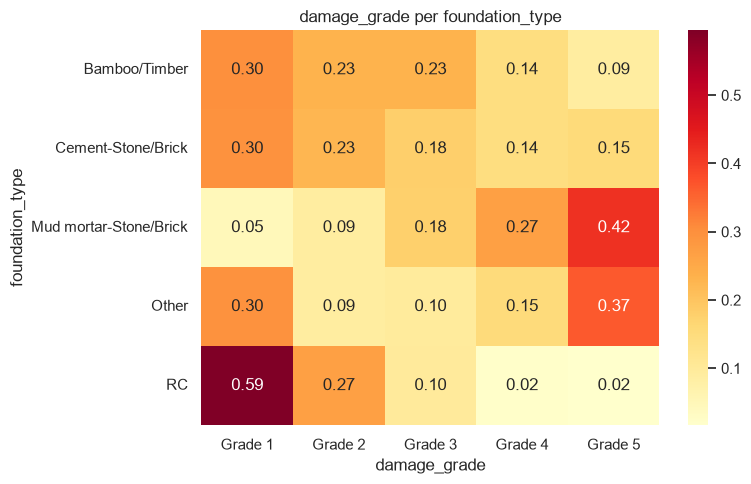

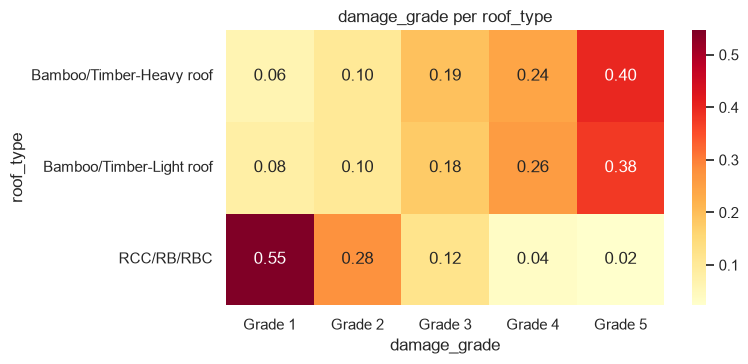

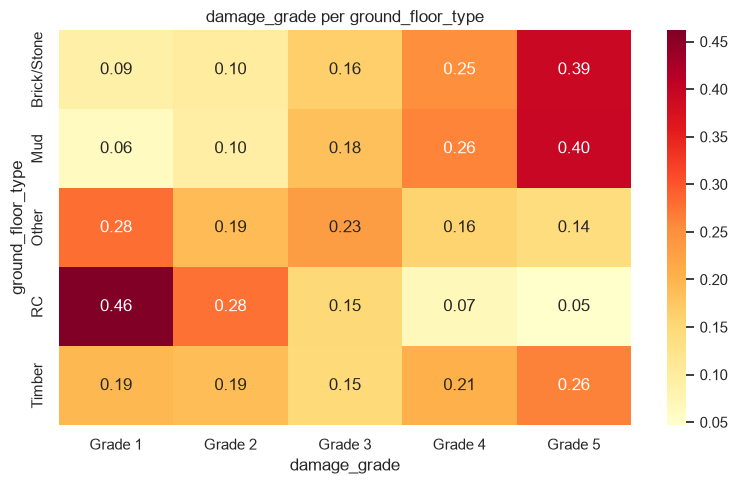

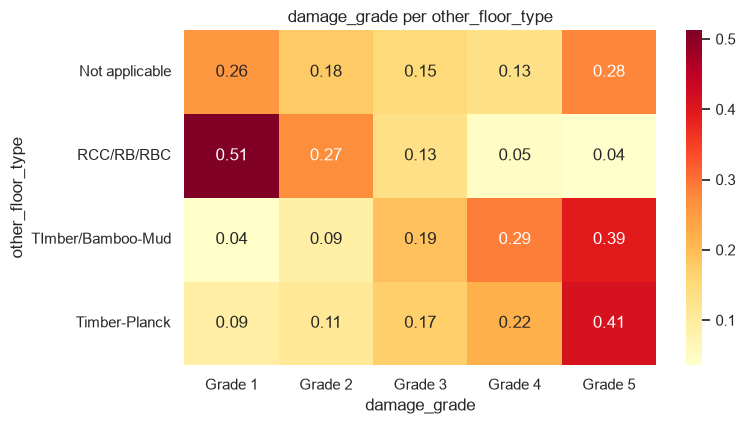

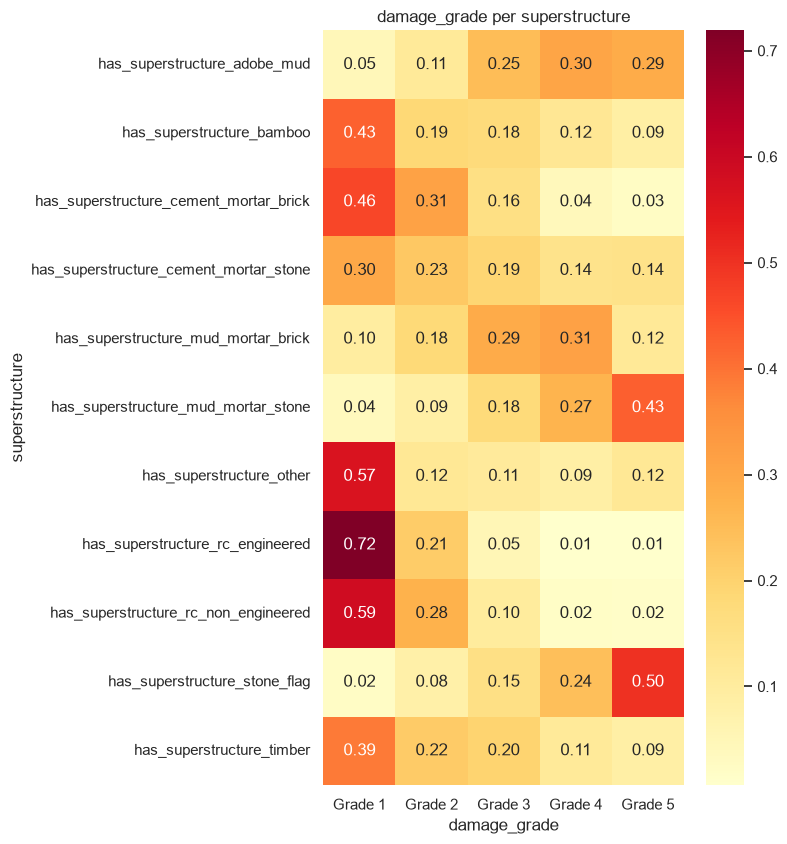

In [10]:
for col in ["foundation_type", "roof_type", "ground_floor_type", "other_floor_type", "superstructure"]:
    plot_target_heatmap(train, col, f"target_by_{col}.png")

heatmap memberikan indikasi yang lebih jelas tentang hubungan kategorikal dengan target daripada tabel frekuensi saja. foundation_type, roof_type, ground_floor_type, other_floor_type, dan superstructure layak dipertahankan untuk eksperimen awal. Namun, heatmap belum menentukan fitur terbaik secara definitif; kontribusinya perlu diuji melalui validasi model.

## 6. Fitur lokasi
`district_id` -> `vdcmun_id` -> `ward_id` adalah hierarki wilayah.

Unik district: 11 | vdcmun: 110 | ward: 945
vdcmun_id // 100 == district_id : 1.0
ward_id // 100 == vdcmun_id     : 1.0
Ward di test yang ada di train  : 1.0


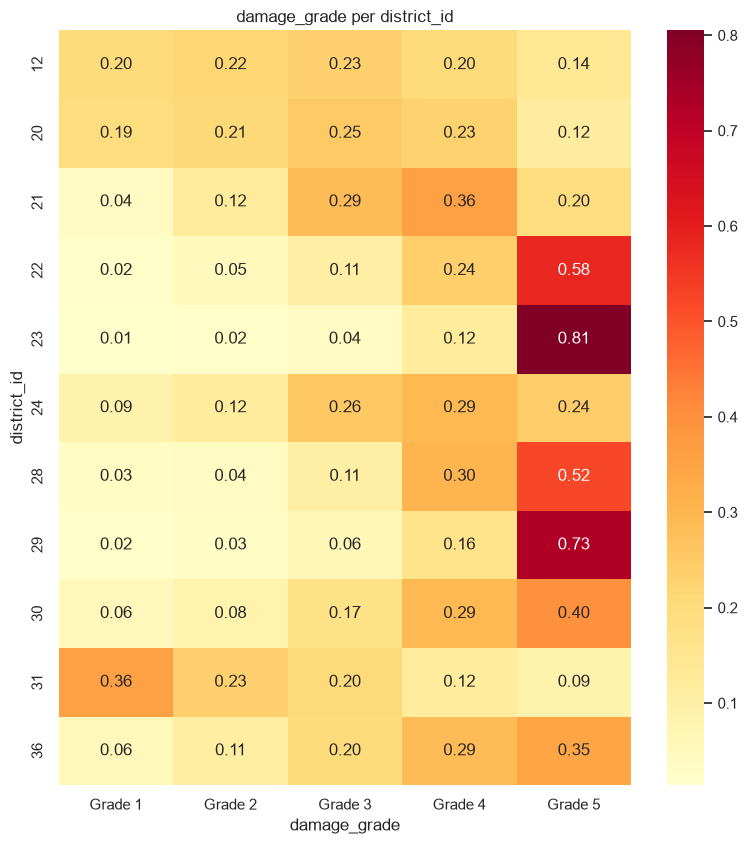

In [11]:
print("Unik district:", train["district_id"].nunique(),
      "| vdcmun:", train["vdcmun_id"].nunique(),
      "| ward:", train["ward_id"].nunique())
print("vdcmun_id // 100 == district_id :", (train["vdcmun_id"] // 100 == train["district_id"]).mean())
print("ward_id // 100 == vdcmun_id     :", (train["ward_id"] // 100 == train["vdcmun_id"]).mean())
print("Ward di test yang ada di train  :", test["ward_id"].isin(train["ward_id"]).mean().round(3))
plot_target_heatmap(train, "district_id", "target_by_district.png")

### Interpretasi Fitur Lokasi terhadap Target

Data memiliki 11 district, 110 VDC/municipality, dan 945 ward. Pemeriksaan hierarki ID menunjukkan bahwa `vdcmun_id // 100` sesuai dengan `district_id` pada seluruh observasi yang diperiksa, dan `ward_id // 100` sesuai dengan `vdcmun_id`. Selain itu, seluruh ward yang terdapat pada test juga ditemukan pada train.

Heatmap distribusi `damage_grade` per district menunjukkan adanya variasi komposisi kelas target antarwilayah. Beberapa district memiliki proporsi Grade 5 yang relatif tinggi, sedangkan district lainnya menunjukkan proporsi yang lebih tersebar pada beberapa kelas. Hal ini mengindikasikan bahwa informasi geografis berpotensi membantu model dalam memprediksi tingkat kerusakan.

Meskipun demikian, perbedaan distribusi tersebut tidak membuktikan bahwa lokasi secara langsung menyebabkan perbedaan tingkat kerusakan. Variasi dapat berkaitan dengan perbedaan karakteristik bangunan, material konstruksi, maupun faktor lainnya. Karena itu, fitur lokasi akan dipertahankan untuk eksperimen dan dievaluasi melalui validasi.

ID wilayah perlu diperlakukan sebagai informasi kategorikal atau hierarkis, bukan otomatis sebagai variabel numerik kontinu. Penggunaan beberapa tingkat ID sekaligus juga perlu diuji untuk mengetahui apakah informasi tambahan yang diberikan meningkatkan performa model.

## 7. Perbandingan train vs test
Jika distribusi test berbeda jauh dari train, validasi lokal bisa menyesatkan.

In [12]:
for col in ["district_id", "foundation_type", "roof_type", "superstructure"]:
    display(compare_train_test(train, test, col))

,train,test
district_id,,
24,0.129,0.129
31,0.119,0.120
30,0.117,0.117
23,0.117,0.116
36,0.103,0.102
28,0.101,0.103
20,0.090,0.090
22,0.080,0.079
21,0.077,0.077


,train,test
foundation_type,,
Mud mortar-Stone/Brick,0.825,0.825
Bamboo/Timber,0.075,0.076
Cement-Stone/Brick,0.052,0.051
RC,0.042,0.042
Other,0.006,0.006


,train,test
roof_type,,
Bamboo/Timber-Light roof,0.661,0.662
Bamboo/Timber-Heavy roof,0.281,0.280
RCC/RB/RBC,0.058,0.059


,train,test
superstructure,,
has_superstructure_mud_mortar_stone,0.779,0.778
has_superstructure_cement_mortar_brick,0.062,0.063
has_superstructure_timber,0.048,0.047
has_superstructure_adobe_mud,0.042,0.043
has_superstructure_rc_non_engineered,0.017,0.017
has_superstructure_stone_flag,0.013,0.013
has_superstructure_mud_mortar_brick,0.013,0.013
has_superstructure_rc_engineered,0.010,0.011
has_superstructure_cement_mortar_stone,0.009,0.009


### Interpretasi Perbandingan Train dan Test

Berdasarkan tabel perbandingan, distribusi kategori pada data train dan test terlihat sangat mirip untuk fitur yang diperiksa.

Pada `district_id`, selisih proporsi antartrain dan test sangat kecil. Sebagai contoh, district 24 memiliki proporsi 0,129 pada kedua dataset, sedangkan district 31 memiliki proporsi 0,119 pada train dan 0,120 pada test.

Pola serupa terlihat pada `foundation_type`. Kategori `Mud mortar-Stone/Brick` memiliki proporsi 0,825 pada train dan test. Pada `roof_type`, kategori `Bamboo/Timber-Light roof` memiliki proporsi 0,661 pada train dan 0,662 pada test. Sementara itu, kategori `has_superstructure_mud_mortar_stone` memiliki proporsi 0,779 pada train dan 0,778 pada test.

Kesamaan proporsi tersebut menunjukkan bahwa tidak terdapat pergeseran distribusi kategori yang mencolok pada empat fitur yang diperiksa. Kondisi ini merupakan indikasi positif karena model akan mempelajari pola dari data train yang memiliki komposisi kategori serupa dengan data test.

Namun, pemeriksaan ini belum membuktikan bahwa seluruh fitur numerik dan kategorikal memiliki distribusi yang sama. Perbandingan proporsi marginal juga belum menunjukkan apakah kombinasi fitur antardataset serupa. Oleh karena itu, pemeriksaan tambahan terhadap fitur numerik dan fitur lainnya tetap diperlukan.

Berdasarkan hasil yang tersedia, tidak ada alasan untuk melakukan penyesuaian distribusi train-test secara khusus hanya pada empat fitur tersebut. Preprocessing dan pemodelan tetap perlu dievaluasi menggunakan validasi yang sesuai.

In [13]:
# === Ringkasan EDA (angka yang dipakai di kesimpulan) ===
print("SHAPE train/test:", train.shape, test.shape)
print("MISSING train/test:", train.isna().sum().sum(), test.isna().sum().sum())
print("TARGET %:", (train[TARGET].value_counts(normalize=True).sort_index() * 100).round(1).to_dict())
print("AGE 999 train/test:", (train["age_building"] == 999).sum(), (test["age_building"] == 999).sum())
print("AGE>=100:", (train["age_building"] >= 100).sum(), "| HEIGHT>=60:", (train["height_ft_pre_eq"] >= 60).sum())
print("MEDIAN per kelas:")
print(train[train["age_building"] < 999].groupby(TARGET)[NUM_COLS].median().round(1).to_string())
print("UNIK kategori train/test:", {c: (train[c].nunique(), test[c].nunique()) for c in CAT_COLS})
print("KATEGORI test tak ada di train:", {c: sorted(set(test[c]) - set(train[c])) for c in CAT_COLS if set(test[c]) - set(train[c])})
print("KATEGORI <1% data:", {c: int((train[c].value_counts(normalize=True) < 0.01).sum()) for c in CAT_COLS})
for c in ["foundation_type", "roof_type", "ground_floor_type", "superstructure", "district_id"]:
    top = pd.crosstab(train[c], train[TARGET], normalize="index")
    print(f"% Grade 5 per {c}:", (top["Grade 5"] * 100).round(0).astype(int).to_dict())
    print(f"% Grade 1 per {c}:", (top["Grade 1"] * 100).round(0).astype(int).to_dict())

SHAPE train/test: (533465, 17) (228629, 16)
MISSING train/test: 0 0
TARGET %: {'Grade 1': 10.3, 'Grade 2': 11.4, 'Grade 3': 17.9, 'Grade 4': 24.1, 'Grade 5': 36.2}
AGE 999 train/test: 2198 946
AGE>=100: 4473 | HEIGHT>=60: 372
MEDIAN per kelas:
              count_floors_pre_eq  age_building  plinth_area_sq_ft  height_ft_pre_eq
damage_grade                                                                        
Grade 1                       2.0           7.0              400.0              14.0
Grade 2                       2.0          12.0              380.0              15.0
Grade 3                       2.0          16.0              364.0              16.0
Grade 4                       2.0          20.0              350.0              16.0
Grade 5                       2.0          20.0              342.0              16.0
UNIK kategori train/test: {'land_surface_condition': (3, 3), 'foundation_type': (5, 5), 'roof_type': (3, 3), 'ground_floor_type': (5, 5), 'other_floor_type': (4,

## 8. Kesimpulan EDA

- **Distribusi target:** Kelas tidak seimbang: Grade 5 sebesar 36,2% dan Grade 1 hanya 10,3%.
  Karena metrik adalah Macro F1, kelas kecil harus sama baiknya dengan kelas besar. Keputusan:
  Stratified K-Fold, `class_weight="balanced"`, dan evaluasi F1 per kelas.

- **Nilai tidak wajar:** `age_building = 999` ada pada 2.198 baris train (0,41%) dan 946 baris
  test (0,41%). Proporsi yang sama di kedua set menunjukkan ini kode "umur tidak diketahui".
  Keputusan: ganti dengan NaN, imputasi median, dan tambah flag `age_unknown`. Selain itu ada
  ±2.275 baris umur 100-998 dan 372 baris tinggi ≥ 60 kaki; tidak dihapus, hanya diredam
  pengaruhnya lewat model berbasis pohon / scaling.

- **Fitur yang berhubungan dengan target:**
  - Lokasi paling kuat: Grade 5 mencapai 81% di distrik 23 dan 73% di distrik 29, tetapi hanya
    9% di distrik 31 (yang justru 36% Grade 1).
  - Material: bangunan RC (59% Grade 1, 2% Grade 5) dan atap RCC (55% Grade 1, 2% Grade 5) jauh
    lebih tahan dibanding fondasi mud mortar-stone/brick (42% Grade 5) dan struktur
    stone flag (50% Grade 5).
  - Numerik: median umur naik dari 7 ke 20 tahun, dan luas dasar turun dari 400 ke 342 sq ft
    dari Grade 1 ke Grade 5. Jumlah lantai tidak membedakan kelas.

- **Kategori langka:** `plan_configuration` punya 7 kategori di bawah 1% data, dan beberapa
  kategori lain (mis. `foundation_type`, `ground_floor_type`) juga sangat kecil. Tidak ada
  kategori di test yang tidak ada di train. Keputusan: One-Hot dengan `min_frequency` untuk
  model linear, dan `handle_unknown` agar aman.

- **Rencana preprocessing dan feature engineering:** `Pipeline` + `ColumnTransformer` (imputasi
  median, scaling, encoding), fitur `height_per_floor` dan `volume_proxy`, ID wilayah dipakai
  sebagai kategori, dan `building_id` dibuang. Model: Logistic Regression sebagai baseline,
  lalu model berbasis pohon (tanpa Neural Network).